In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [2]:
sns.set_theme(style="whitegrid")

In [3]:
df_income  = pd.read_csv('../data/processed/01_income_statement.csv')
df_balance = pd.read_csv('../data/processed/02_balance_sheet.csv')
df_stock   = pd.read_csv('../data/processed/04_stock_price.csv')

In [4]:
df_income_trend = df_income[df_income['is_outlier_year'] == False].copy()

In [5]:
X_revenue = df_income_trend[['fy_num']]
y_revenue = df_income_trend['revenue_eur_m']

In [6]:
model_revenue = LinearRegression()
model_revenue.fit(X_revenue, y_revenue)
model_revenue

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [7]:
y_pred_revenue = model_revenue.predict(X_revenue)
r2_revenue = r2_score(y_revenue, y_pred_revenue)
print(y_pred_revenue)
print(r2_revenue)

[11206.2 12687.4 14168.6 15649.8]
0.9306222270559682


In [8]:
FORECAST_FY = 2027
revenue_forecast = model_revenue.predict(pd.DataFrame({'fy_num': [FORECAST_FY]}))[0]

In [9]:
print("\n--- 1. REVENUE TREND REGRESSION ---")
print(f"Slope (EUR M per fiscal year): {model_revenue.coef_[0]:.0f}")
print(f"Intercept: {model_revenue.intercept_:.0f}")
print(f"R-squared: {r2_revenue:.3f}")
print(f"Forecast FY{FORECAST_FY} revenue: {revenue_forecast:,.0f} EUR M")
print("NOTE: only 4 data points went into this line - treat it as a trend estimate, not a robust forecast.")


--- 1. REVENUE TREND REGRESSION ---
Slope (EUR M per fiscal year): 1481
Intercept: -2985261
R-squared: 0.931
Forecast FY2027 revenue: 17,131 EUR M
NOTE: only 4 data points went into this line - treat it as a trend estimate, not a robust forecast.


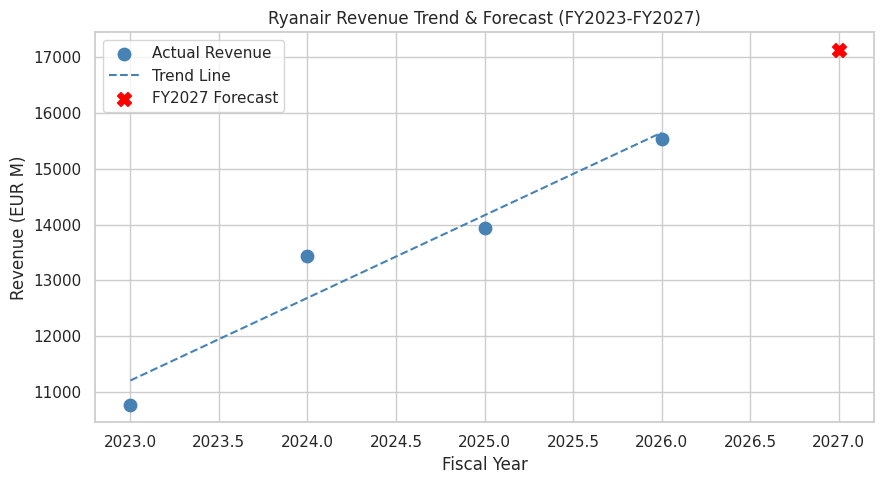

In [10]:
plt.figure(figsize=(9, 5))
plt.scatter(df_income_trend['fy_num'], df_income_trend['revenue_eur_m'], color='steelblue', s=80, label='Actual Revenue')
plt.plot(df_income_trend['fy_num'], y_pred_revenue, color='steelblue', linestyle='--', label='Trend Line')
plt.scatter([FORECAST_FY], [revenue_forecast], color='red', s=100, marker='X', label=f'FY{FORECAST_FY} Forecast')
plt.title('Ryanair Revenue Trend & Forecast (FY2023-FY2027)')
plt.xlabel('Fiscal Year')
plt.ylabel('Revenue (EUR M)')
plt.legend()
plt.tight_layout()
plt.savefig('../reports/figures/forecast_01_revenue_trend.png', dpi=120)
plt.show()

In [11]:
X_stock = df_stock[['year']]
y_stock = df_stock['average_price_usd']

In [12]:
model_stock = LinearRegression()
model_stock.fit(X_stock, y_stock)
model_stock

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [13]:
y_pred_stock = model_stock.predict(X_stock)
r2_stock = r2_score(y_stock, y_pred_stock)
print(y_pred_stock)
print(r2_stock)

[15.21563833 17.92582619 20.63601405 23.3462019  26.05638976 28.76657762
 31.47676548 34.18695333 36.89714119 39.60732905 42.3175169  45.02770476
 47.73789262 50.44808048 53.15826833]
0.7775265858063575


In [14]:
FORECAST_YEAR = 2027
stock_forecast = model_stock.predict(pd.DataFrame({'year': [FORECAST_YEAR]}))[0]

In [15]:
print("\n--- 2. STOCK PRICE TREND REGRESSION ---")
print(f"Slope (USD per year): {model_stock.coef_[0]:.2f}")
print(f"Intercept: {model_stock.intercept_:.2f}")
print(f"R-squared: {r2_stock:.3f}")
print(f"Forecast {FORECAST_YEAR} average price: ${stock_forecast:.2f}")


--- 2. STOCK PRICE TREND REGRESSION ---
Slope (USD per year): 2.71
Intercept: -5437.68
R-squared: 0.778
Forecast 2027 average price: $55.87


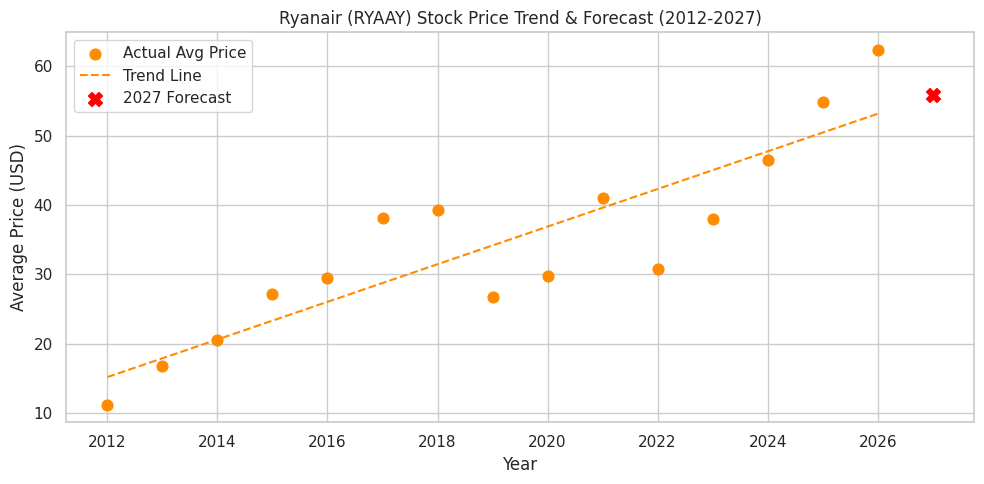

In [16]:
plt.figure(figsize=(10, 5))
plt.scatter(df_stock['year'], df_stock['average_price_usd'], color='darkorange', s=60, label='Actual Avg Price')
plt.plot(df_stock['year'], y_pred_stock, color='darkorange', linestyle='--', label='Trend Line')
plt.scatter([FORECAST_YEAR], [stock_forecast], color='red', s=100, marker='X', label=f'{FORECAST_YEAR} Forecast')
plt.title('Ryanair (RYAAY) Stock Price Trend & Forecast (2012-2027)')
plt.xlabel('Year')
plt.ylabel('Average Price (USD)')
plt.legend()
plt.tight_layout()
plt.savefig('../reports/figures/forecast_02_stock_trend.png', dpi=120)
plt.show()

In [17]:
X_margin = df_balance[['debt_to_equity']]
y_margin = df_income['operating_margin_pct']

In [18]:
model_margin = LinearRegression()
model_margin.fit(X_margin, y_margin)
model_margin

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [19]:
y_pred_margin = model_margin.predict(X_margin)
r2_margin = r2_score(y_margin, y_pred_margin)
print(y_pred_margin)
print(r2_margin)

[-0.05184779  4.36932956 13.06982831 12.59697511 18.10571481]
0.5946242800680621


In [20]:
print("\n--- 3. PROFITABILITY DRIVER REGRESSION (Operating Margin ~ Debt-to-Equity) ---")
margin_coef = model_margin.coef_[0]
print(f"Coefficient: {margin_coef:.2f}")
if margin_coef < 0:
    print("Negative coefficient: higher leverage lines up with LOWER operating margins.")
else:
    print("Positive coefficient: higher leverage lines up with HIGHER operating margins.")
print(f"R-squared: {r2_margin:.3f}")
print("CAVEAT: only 5 data points (one company's fiscal years) - nowhere near enough")
print("to treat this as proof. Sklearn doesn't test significance the way stats software")
print("does, so read this as a descriptive trend, not a confirmed driver.")


--- 3. PROFITABILITY DRIVER REGRESSION (Operating Margin ~ Debt-to-Equity) ---
Coefficient: -23.64
Negative coefficient: higher leverage lines up with LOWER operating margins.
R-squared: 0.595
CAVEAT: only 5 data points (one company's fiscal years) - nowhere near enough
to treat this as proof. Sklearn doesn't test significance the way stats software
does, so read this as a descriptive trend, not a confirmed driver.


In [21]:
df_forecast_summary = pd.DataFrame({
    'metric': ['Revenue (EUR M)', 'Stock Price (USD)'],
    'model_r_squared': [round(r2_revenue, 3), round(r2_stock, 3)],
    'forecast_year': [FORECAST_FY, FORECAST_YEAR],
    'forecast_value': [round(revenue_forecast, 1), round(stock_forecast, 2)]
})
df_forecast_summary.to_csv('../data/processed/06_forecast_summary.csv', index=False)
 
print("\nSuccess! Forecast summary exported to: mine_01_forecast_summary.csv")
print("Success! 2 charts saved to current folder")


Success! Forecast summary exported to: mine_01_forecast_summary.csv
Success! 2 charts saved to current folder
